In [1]:
import os

import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch
import seaborn as sns

from statsmodels.tsa.api import VAR

from tv_var.harmonic_standardizer import HarmonicStandardizer
from tv_var.periodic_var import PeriodicVAR

In [3]:
#### Load Data
path_pcs = os.path.join("..", "..", "inputs", "pcs_df.csv")
pcs_df = pd.read_csv(path_pcs, index_col=0, parse_dates=True)

#### Inputs
n_harmonics = 0

#### Path_outputs
name_model = f'var_zs_nh_3_monthly_resid'
path_output = os.path.join("..", "..", "outputs", "model_comp", f"{name_model}.nc")

In [4]:
harm_std = HarmonicStandardizer(n_harmonics=3)
harm_std.fit(pcs_df)
zs_df = harm_std.transform(pcs_df)

In [5]:
tv_var = PeriodicVAR(p=5, n_harm=n_harmonics, noise="monthly")
tv_var.fit(zs_df)

31 regressors per equation, 31680 days
Stable every day: True   (max 0.835 on day 1)


/tmp/ipykernel_88451/2474225203.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  ax.set_xticks(pd.date_range("2001-01-01", periods=12, freq="MS").dayofyear)


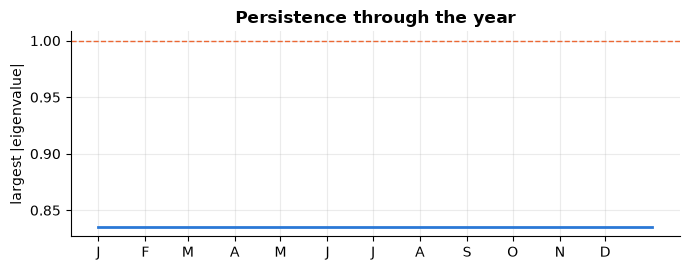

In [6]:
stab  = tv_var.stability()
print(f"{len(tv_var.coef_table_)} regressors per equation, {tv_var.nobs_} days")
print(f"Stable every day: {(stab < 1).all()}   (max {stab.max():.3f} on day {stab.idxmax()})")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(stab.index, stab.values, color="#2a78d6", lw=2)
ax.axhline(1, color="#eb6834", lw=1, ls="--")
ax.set_xticks(pd.date_range("2001-01-01", periods=12, freq="MS").dayofyear)
ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_ylabel("largest |eigenvalue|"); ax.set_title("Persistence through the year", fontweight="bold")
ax.grid(alpha=0.25)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fig.tight_layout(); plt.show()

In [7]:
from tqdm.auto import tqdm

#### Simulate
N_SIMS = 100
BURN   = 365
dates  = pcs_df.index
n_years = len(dates) / 365.25

simulations_list = []
for sim_idx in tqdm(range(N_SIMS), desc="Simulating"):
    z_df = tv_var.simulate(n_years=n_years, start=dates[0], seed=sim_idx, burn=BURN)
    assert z_df.index.equals(dates), "simulated calendar differs from ERA5"
    simulations_list.append(harm_std.inverse_transform(z_df))

print(len(simulations_list), "records of", simulations_list[0].shape)

Simulating:   0%|          | 0/100 [00:00<?, ?it/s]

100 records of (31685, 6)


In [8]:
#### Save
simulations_list_xr = [df.to_xarray() for df in simulations_list]

sim = xr.concat(simulations_list_xr, dim='seed')
sim = sim.to_array('pc').rename({'index': 'time'}).transpose('seed', 'time', 'pc').rename('pcs')
sim.to_netcdf(path_output)

In [9]:
sim_0_df = sim.isel(seed=0).to_pandas()

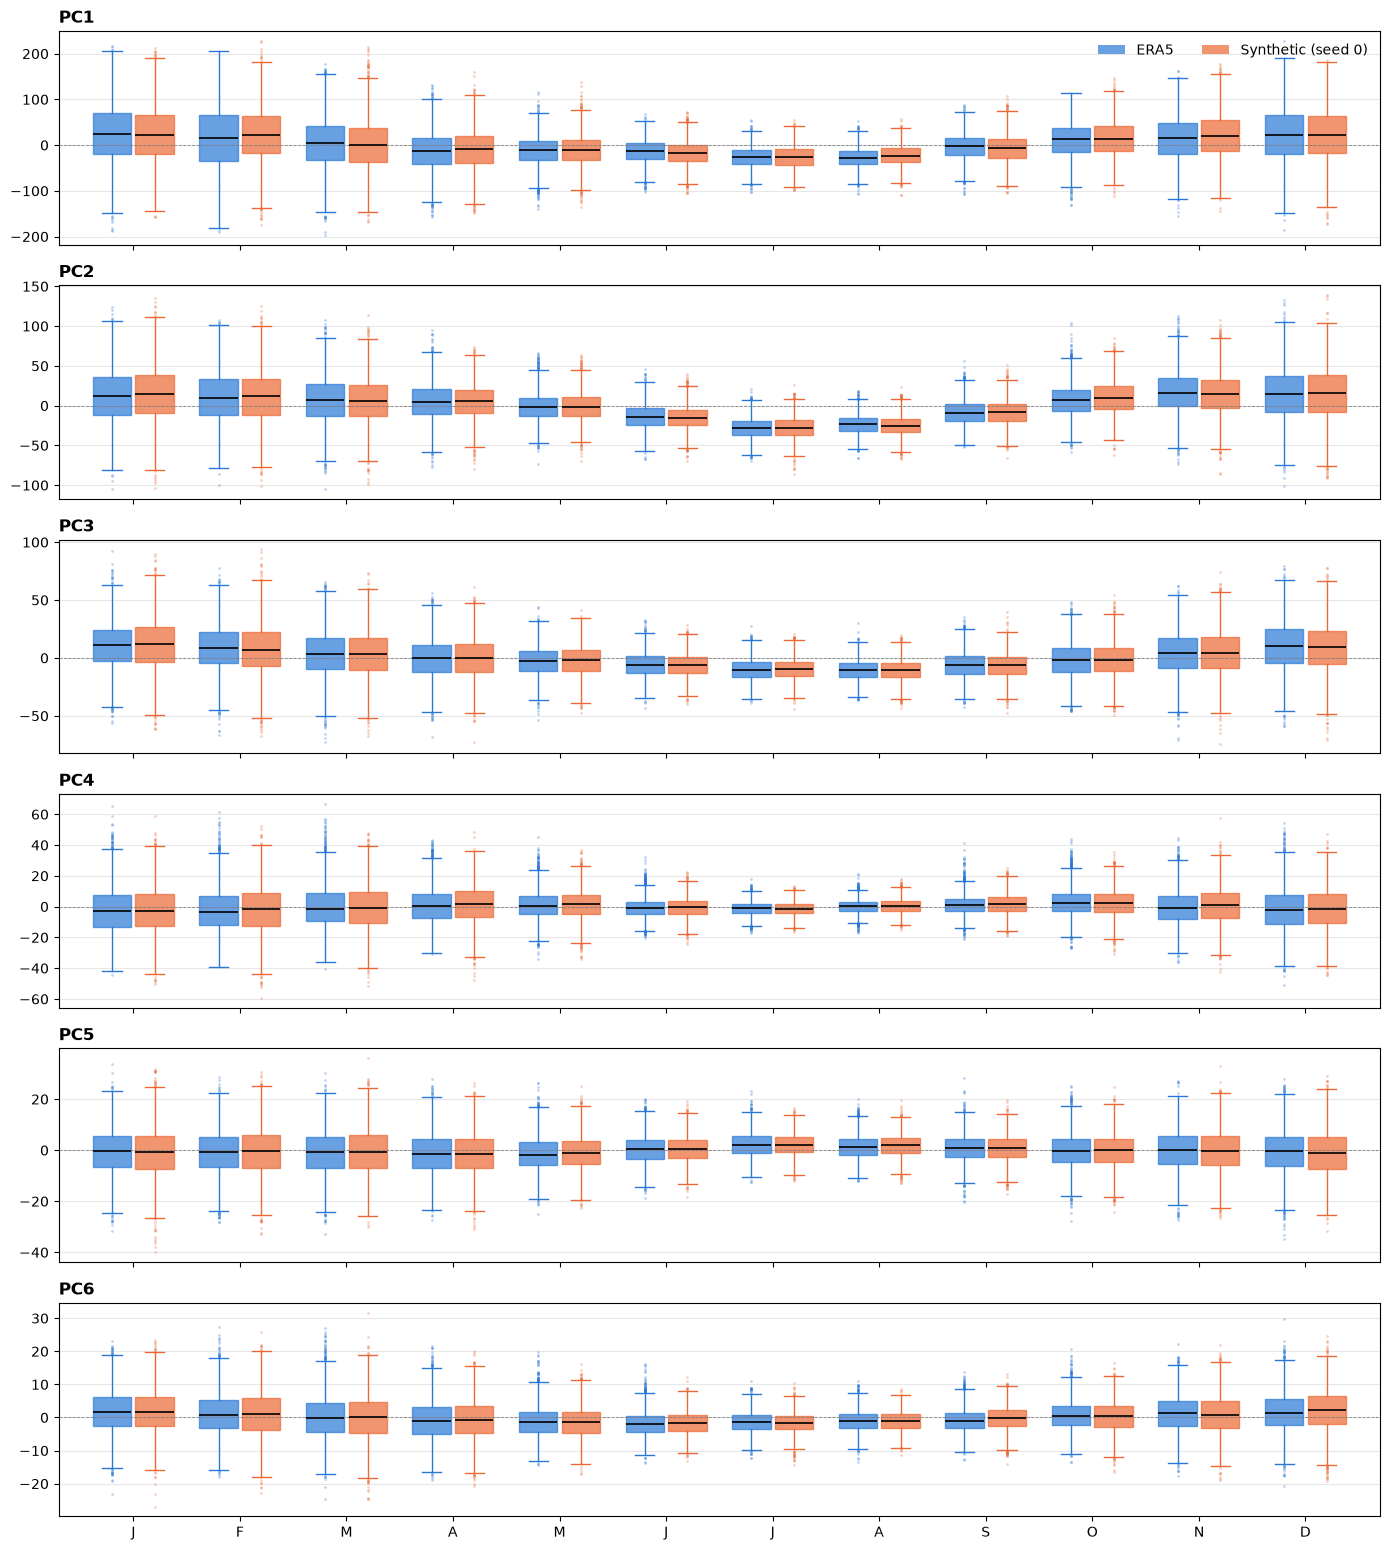

In [10]:
def monthly_boxplots(dfs, colors, pcs=None):
    """dfs: {label: DataFrame with DatetimeIndex}. One row per PC, boxes side by side per month."""
    pcs    = pcs or list(next(iter(dfs.values())).columns)
    months = np.arange(1, 13)
    n      = len(dfs)
    width  = 0.8 / n

    fig, axes = plt.subplots(len(pcs), 1, figsize=(14, 2.6 * len(pcs)), sharex=True)
    for ax, pc in zip(np.atleast_1d(axes), pcs):
        for i, (label, df) in enumerate(dfs.items()):
            data = [df.loc[df.index.month == m, pc].values for m in months]
            pos  = months - 0.4 + width * (i + 0.5)
            bp = ax.boxplot(data, positions=pos, widths=width * 0.9, patch_artist=True,
                            flierprops=dict(marker=".", markersize=2, alpha=0.3,
                                            markeredgecolor=colors[label]),
                            medianprops=dict(color="black", lw=1.2),
                            whiskerprops=dict(color=colors[label]),
                            capprops=dict(color=colors[label]))
            for box in bp["boxes"]:
                box.set(facecolor=colors[label], alpha=0.7, edgecolor=colors[label])
        ax.set_title(pc, loc="left", fontweight="bold")
        ax.axhline(0, color="grey", lw=0.6, ls="--")
        ax.grid(axis="y", alpha=0.3)
    axes[-1].set_xticks(months)
    axes[-1].set_xticklabels(list("JFMAMJJASOND"))
    axes[0].legend(handles=[Patch(facecolor=c, alpha=0.7, label=l) for l, c in colors.items()],
                   loc="upper right", ncol=n, frameon=False)
    fig.tight_layout()
    return fig

monthly_boxplots({"ERA5": pcs_df, "Synthetic (seed 0)": sim_0_df},
                 colors={"ERA5": "#2a78d6", "Synthetic (seed 0)": "#eb6834"})
plt.show()

In [11]:
pcs_list = pcs_df.columns.to_list()

auto_corr = {}

for pc in pcs_list:
    era5_aux_df = pcs_df[[pc]].copy()
    for i in range(1,11,1):
        era5_aux_df[f'{pc}_lag_{i}']= era5_aux_df[pc].shift(i)

    era5_aux_df['month'] = era5_aux_df.index.month
    for month in range(1,13,1):
        aux_df = era5_aux_df[era5_aux_df['month'] == month].copy()
        aux_df = aux_df.drop(columns='month')
        auto_corr[f'{pc}_month_{month}'] = aux_df.corr().values[:,0]

In [12]:
def acf_by_month(df, max_lag=10):
    """{f'{pc}_month_{m}': [1, r1, ..., r_max_lag]} on the given (standardized) data."""
    auto_corr = {}
    for pc in df.columns:
        era5_aux_df = df[[pc]].copy()
        for i in range(1, max_lag + 1):
            era5_aux_df[f'{pc}_lag_{i}'] = era5_aux_df[pc].shift(i)

        era5_aux_df['month'] = era5_aux_df.index.month
        for month in range(1, 13):
            aux_df = era5_aux_df[era5_aux_df['month'] == month].drop(columns='month')
            auto_corr[f'{pc}_month_{month}'] = aux_df.corr().values[:, 0]
    return auto_corr

zs_df   = harm_std.transform(pcs_df)            # ERA5 on z
acf_obs = acf_by_month(zs_df)

acf_sims = [acf_by_month(harm_std.transform(sim.isel(seed=s).to_pandas()))
            for s in range(sim.sizes["seed"])]

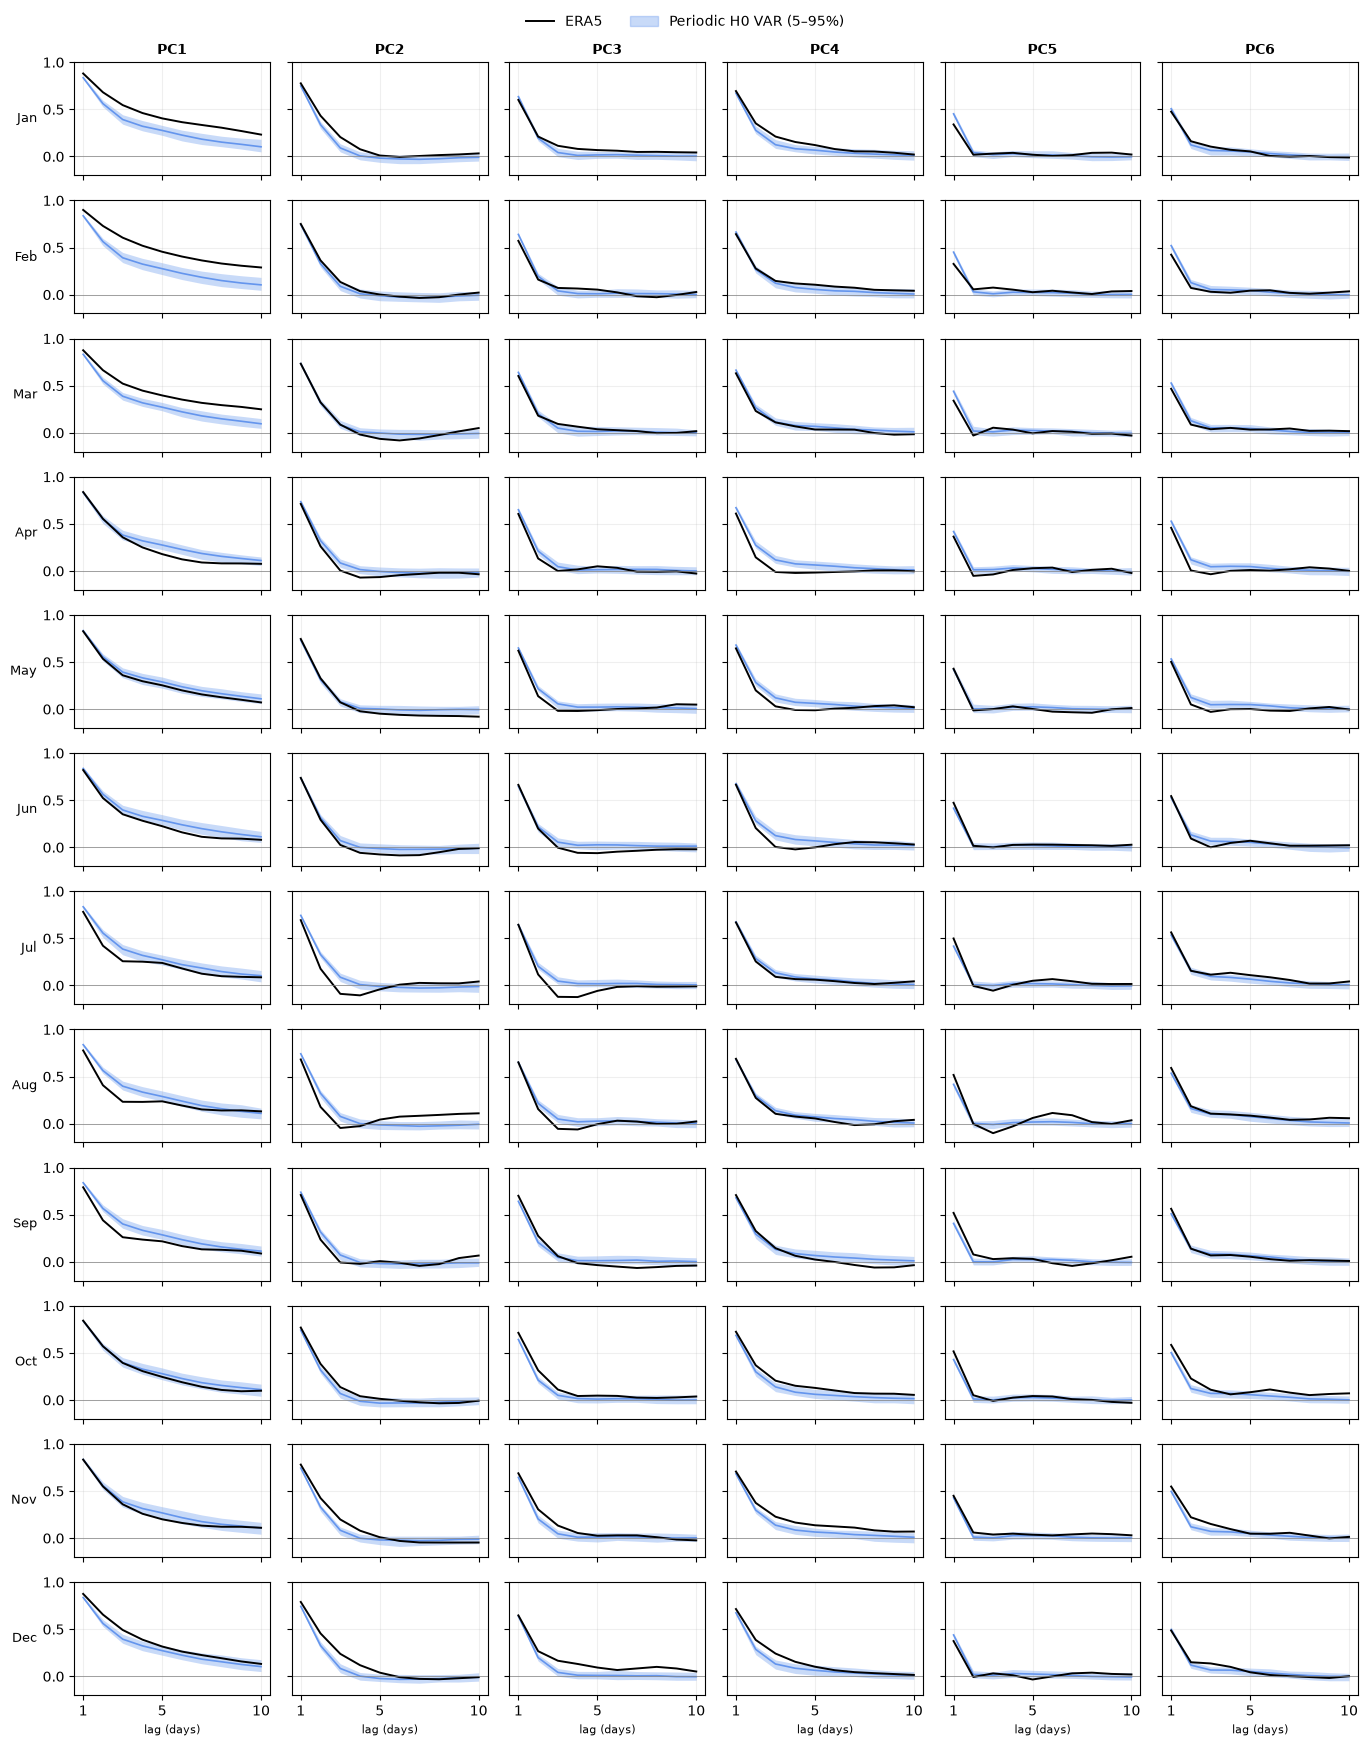

In [13]:
months = range(1, 13)
lags   = np.arange(1, 11)
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, axes = plt.subplots(12, len(pcs_list), figsize=(2.3 * len(pcs_list), 1.45 * 12),
                         sharex=True, sharey=True)

for i, m in enumerate(months):
    for j, pc in enumerate(pcs_list):
        ax  = axes[i, j]
        key = f'{pc}_month_{m}'
        sim = np.array([a[key][1:] for a in acf_sims])          # records x lags (drop lag 0)
        lo, hi = np.percentile(sim, [5, 95], axis=0)

        ax.fill_between(lags, lo, hi, color="cornflowerblue", alpha=0.35, lw=0)
        ax.plot(lags, np.median(sim, axis=0), color="cornflowerblue", lw=1.2)
        ax.plot(lags, acf_obs[key][1:], color="black", lw=1.4)
        ax.axhline(0, color="grey", lw=0.5)
        ax.grid(alpha=0.2)

        if i == 0:  ax.set_title(pc, fontsize=10, fontweight="bold")
        if j == 0:  ax.set_ylabel(month_names[m - 1], fontsize=9, rotation=0, ha="right", va="center")

axes[0, 0].set_ylim(-0.2, 1.0)
axes[0, 0].set_xticks([1, 5, 10])
for ax in axes[-1]: ax.set_xlabel("lag (days)", fontsize=8)

handles = [plt.Line2D([], [], color="black", lw=1.4, label="ERA5"),
           plt.Rectangle((0, 0), 1, 1, color="cornflowerblue", alpha=0.35, label=f"Periodic H{n_harmonics} VAR (5–95%)")]
fig.legend(handles=handles, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.005))
fig.tight_layout(rect=(0, 0, 1, 0.99))
plt.show()